# Academic Performance Prediction Using Supervised Learning
## Notebook 3 of 4 — Exam Score Prediction (Regression)

**Objective 2:** predict the continuous target `exam_score` (0–100) from academic, psychological and lifestyle factors.

**Selected features** (per the capstone feature-selection study)

| Type | Features |
|---|---|
| Numeric | previous GPA, motivation, stress–anxiety score, study–sleep ratio, total screen time, time management, attendance |
| Categorical | gender, major, learning style, study environment, **dropout risk**, part-time job, access to tutoring |

**Models compared**

1. Random Forest regressor (baseline)
2. XGBoost regressor (baseline)
3. Support Vector Regressor (baseline)
4. **Hybrid RF + XGBoost stacking ensemble** ← the capstone's proposed model

**Metrics:** R², RMSE, MAE (best model selected on R²). The model is saved to `models/best_exam_model.pkl`.

> `dropout_risk` is an input feature here — at inference time the app feeds in the label predicted by notebook 2's classifier.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

from src.config import (EXAM_CATEGORICAL, EXAM_MODEL_PATH, EXAM_NUMERIC,
                        FIGURES_DIR, METRICS_DIR, RANDOM_STATE, SVM_MAX_ROWS, TEST_SIZE)
from src.features import add_features, build_preprocessor, feature_importance
from src.inference import save_bundle
from src.selection import select_best

sns.set_theme(style="whitegrid", palette="deep")

### 1. Load the cleaned data and engineer the features

In [2]:
df = pd.read_csv("data/processed/cleaned.csv")
df = add_features(df)          # screen_time_total, study_sleep_ratio, stress_anxiety

y = df["exam_score"].astype(float)
X = df.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print(f"train: {len(X_train):,} rows | test: {len(X_test):,} rows")
print(f"target  : exam_score  mean={y.mean():.1f}  std={y.std():.1f}")
print(f"features: {len(EXAM_NUMERIC)} numeric + {len(EXAM_CATEGORICAL)} categorical")

train: 63,070 rows | test: 15,768 rows
target  : exam_score  mean=89.4  std=11.2
features: 7 numeric + 7 categorical


### 2. Models

The hybrid ensemble follows the capstone pseudocode:

```
RF     <- RandomForestRegressor(n_estimators = 150)
XGB    <- XGBoostRegressor(n_estimators = 150, learning_rate = 0.05, max_depth = 5)
XGB_C  <- XGBoostRegressor(n_estimators = 100, learning_rate = 0.05, max_depth = 4)
H      <- StackingRegressor(estimators = {RF, XGB}, final_estimator = XGB_C,
                             passthrough = False)
```

In [3]:
rf = RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1)
xgb = XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=5,
                   random_state=RANDOM_STATE, n_jobs=-1)
meta = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=4,
                    random_state=RANDOM_STATE, n_jobs=-1)

hybrid = StackingRegressor(estimators=[("rf", rf), ("xgb", xgb)],
                           final_estimator=meta, passthrough=False, cv=5, n_jobs=-1)

models = {
    "Random Forest": Pipeline([
        ("preprocess", build_preprocessor(EXAM_NUMERIC, EXAM_CATEGORICAL)),
        ("model", RandomForestRegressor(n_estimators=150,
                                        random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "XGBoost": Pipeline([
        ("preprocess", build_preprocessor(EXAM_NUMERIC, EXAM_CATEGORICAL)),
        ("model", XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=5,
                               random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "SVR (RBF Kernel)": Pipeline([
        ("preprocess", build_preprocessor(EXAM_NUMERIC, EXAM_CATEGORICAL)),
        ("model", SVR(kernel="rbf")),
    ]),
    "Hybrid RF-XGBoost (Stacking)": Pipeline([
        ("preprocess", build_preprocessor(EXAM_NUMERIC, EXAM_CATEGORICAL)),
        ("model", hybrid),
    ]),
}
print(f"{len(models)} models configured")

4 models configured


### 3. Train and evaluate

The SVR baseline is quadratic in the sample count, so it trains on a capped subsample while the other models use the full training split.

In [4]:
svr_cap = min(SVM_MAX_ROWS, len(X_train))
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_train), svr_cap, replace=False)
X_svr, y_svr = X_train.iloc[idx], y_train.iloc[idx]

results, fitted, predictions = {}, {}, {}

for name, pipeline in models.items():
    fit_X, fit_y = (X_svr, y_svr) if name.startswith("SVR") else (X_train, y_train)
    print(f"training {name} on {len(fit_X):,} rows ...", flush=True)

    pipeline.fit(fit_X, fit_y)
    y_pred = pipeline.predict(X_test)

    results[name] = {
        "r2": r2_score(y_test, y_pred),
        "rmse": float(np.sqrt(mean_squared_error(y_test, y_pred))),
        "mae": mean_absolute_error(y_test, y_pred),
        "train_rows": len(fit_X),
    }
    fitted[name] = pipeline
    predictions[name] = y_pred
    print(f"    R2={results[name]['r2']:.4f}  "
          f"RMSE={results[name]['rmse']:.3f}  MAE={results[name]['mae']:.3f}")

training Random Forest on 63,070 rows ...


    R2=0.8618  RMSE=4.179  MAE=3.279
training XGBoost on 63,070 rows ...


    R2=0.8659  RMSE=4.117  MAE=3.206
training SVR (RBF Kernel) on 10,000 rows ...


    R2=0.8476  RMSE=4.389  MAE=3.277
training Hybrid RF-XGBoost (Stacking) on 63,070 rows ...


    R2=0.8654  RMSE=4.125  MAE=3.217


### 4. Results

In [5]:
results_df = pd.DataFrame(results).T[["r2", "rmse", "mae", "train_rows"]]
results_df = results_df.astype({"train_rows": int})
print(results_df.round(4).sort_values("r2", ascending=False).to_string())

best_name = select_best(results, "r2")  # equivalence margin, hybrid preferred
print(f"\nBest model (by R2): {best_name}")

                                  r2    rmse     mae  train_rows
XGBoost                       0.8659  4.1175  3.2057       63070
Hybrid RF-XGBoost (Stacking)  0.8654  4.1252  3.2175       63070
Random Forest                 0.8618  4.1790  3.2792       63070
SVR (RBF Kernel)              0.8476  4.3888  3.2767       10000

Best model (by R2): Hybrid RF-XGBoost (Stacking)


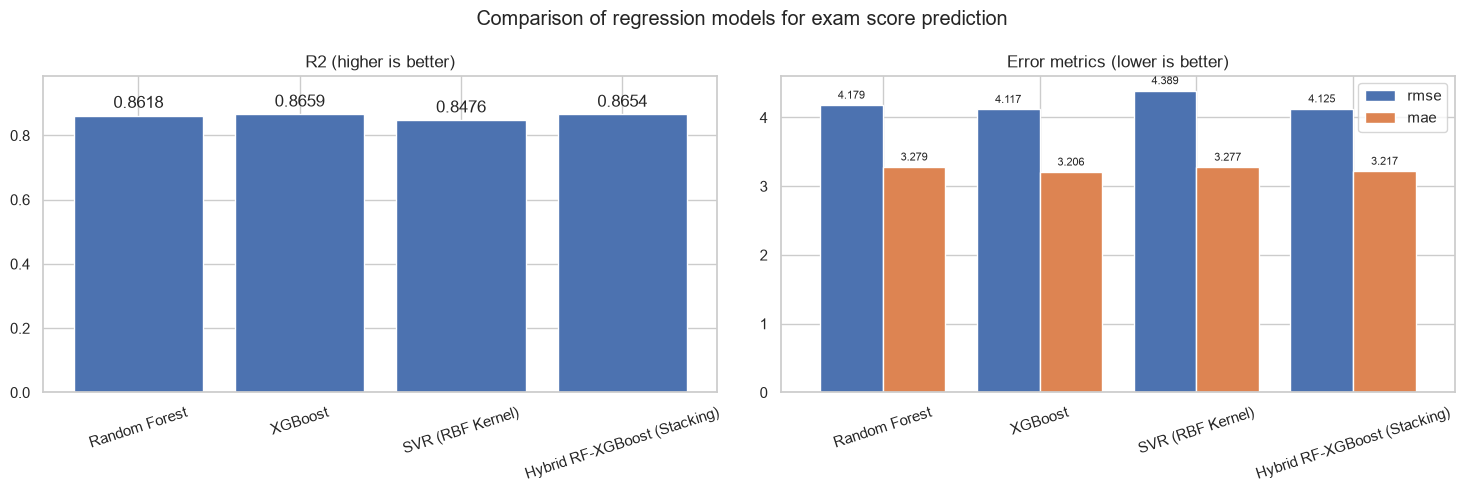

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

r2 = results_df["r2"].astype(float)
bars = ax[0].bar(r2.index, r2.values, color="#4c72b0")
ax[0].bar_label(bars, fmt="%.4f", padding=3)
ax[0].set_ylim(0, min(1.05, r2.max() + 0.12))
ax[0].set_title("R2 (higher is better)")
ax[0].tick_params(axis="x", rotation=18)

err = results_df[["rmse", "mae"]].astype(float)
bars = err.plot(kind="bar", ax=ax[1], rot=18, width=0.8)
for container in bars.containers:
    bars.bar_label(container, fmt="%.3f", padding=3, fontsize=8)
ax[1].set_title("Error metrics (lower is better)")

fig.suptitle("Comparison of regression models for exam score prediction")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eval_regression_comparison.png", dpi=150,
            bbox_inches="tight")
plt.show()

### 5. Best model diagnostics - predicted vs actual, residuals

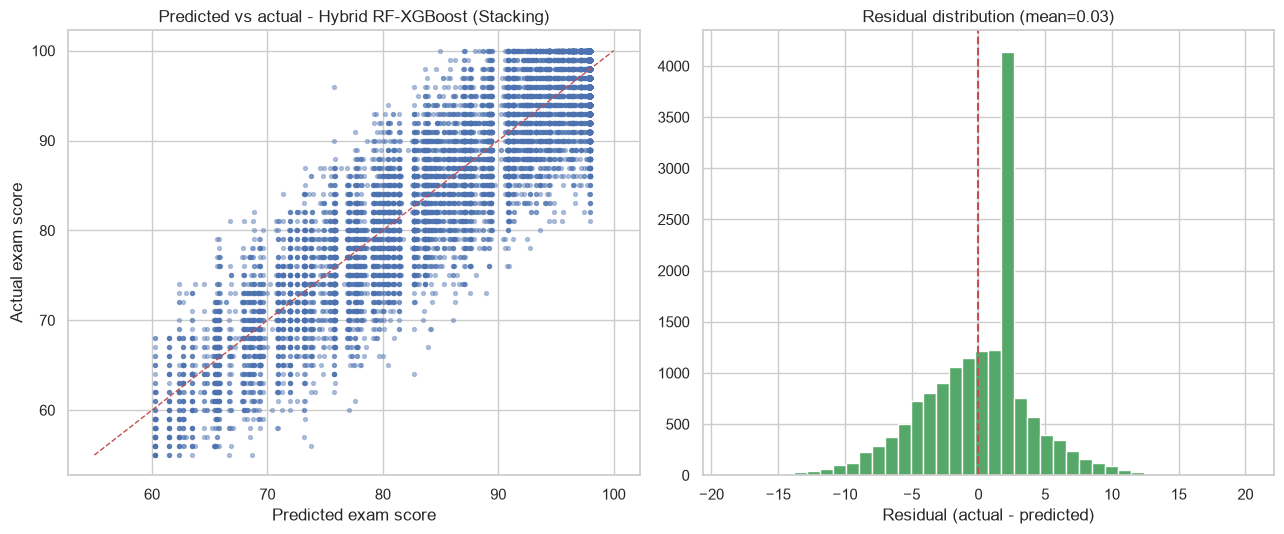

In [7]:
best = fitted[best_name]
y_pred_best = predictions[best_name]
residuals = y_test - y_pred_best

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
ax[0].scatter(y_pred_best, y_test, s=8, alpha=0.4, color="#4c72b0")
lo = min(y_test.min(), y_pred_best.min())
hi = max(y_test.max(), y_pred_best.max())
ax[0].plot([lo, hi], [lo, hi], "r--", linewidth=1)
ax[0].set_xlabel("Predicted exam score")
ax[0].set_ylabel("Actual exam score")
ax[0].set_title(f"Predicted vs actual - {best_name}")

ax[1].hist(residuals, bins=40, color="#55a868", edgecolor="white")
ax[1].axvline(0, color="r", linestyle="--")
ax[1].set_xlabel("Residual (actual - predicted)")
ax[1].set_title(f"Residual distribution (mean={residuals.mean():.2f})")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eval_regression_diagnostics.png", dpi=150,
            bbox_inches="tight")
plt.show()

### 6. Feature importance (tree-based models)

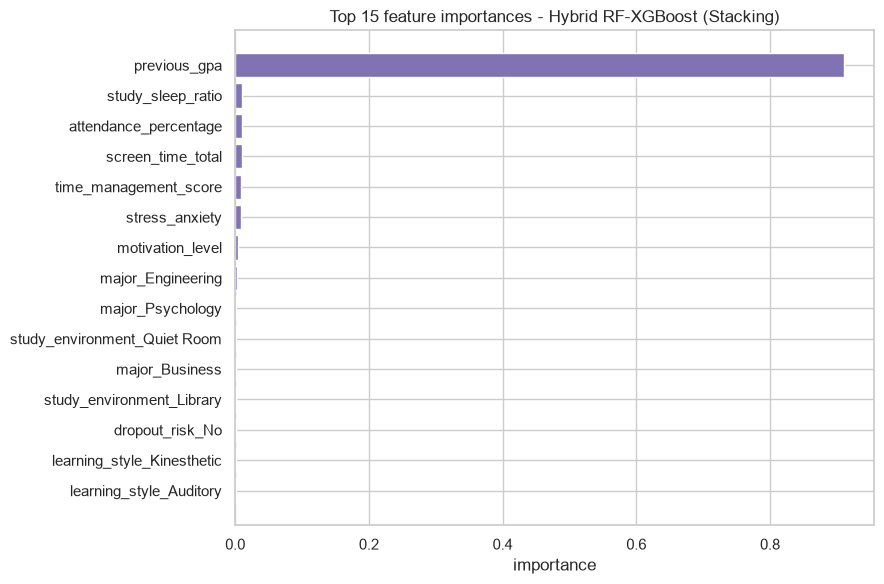

In [8]:
importances = feature_importance(best, EXAM_NUMERIC, EXAM_CATEGORICAL)

if importances:
    top = importances[:15][::-1]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh([name for name, _ in top], [value for _, value in top], color="#8172b3")
    ax.set_title(f"Top {len(top)} feature importances - {best_name}")
    ax.set_xlabel("importance")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "eval_exam_feature_importance.png", dpi=150,
                bbox_inches="tight")
    plt.show()
else:
    print(f"{best_name} does not expose feature importances "
          "(stacking meta-model); the Random Forest baseline does:")
    rf_pipe = fitted["Random Forest"]
    for name, value in feature_importance(rf_pipe, EXAM_NUMERIC, EXAM_CATEGORICAL)[:10]:
        print(f"  {name:32s} {value:.4f}")

### 7. Save the best model

In [9]:
METRICS_DIR.mkdir(parents=True, exist_ok=True)
EXAM_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

save_bundle(
    EXAM_MODEL_PATH,
    best,
    EXAM_NUMERIC,
    EXAM_CATEGORICAL,
    {"best": best_name, "all": results},
    best_name,
)
results_df.round(4).to_csv(METRICS_DIR / "exam_results.csv")

print(f"saved -> {EXAM_MODEL_PATH}")
print(f"best model: {best_name}")
print(f"R2={results[best_name]['r2']:.4f}  "
      f"RMSE={results[best_name]['rmse']:.3f}  "
      f"MAE={results[best_name]['mae']:.3f}")

saved -> D:\Downloads\freebuff\models\best_exam_model.pkl
best model: Hybrid RF-XGBoost (Stacking)
R2=0.8654  RMSE=4.125  MAE=3.217


### 8. Write the combined metrics summary

`reports/metrics/metrics.json` holds the data-cleaning stats and both model tables.

In [10]:
import json

drop_df = pd.read_csv(METRICS_DIR / "dropout_results.csv", index_col=0)
exam_df = pd.read_csv(METRICS_DIR / "exam_results.csv", index_col=0)

summary = {
    "dropout": {"best": select_best(drop_df.to_dict("index"), "f1"),
                "results": drop_df.to_dict("index")},
    "exam_score": {"best": select_best(exam_df.to_dict("index"), "r2"),
                   "results": exam_df.to_dict("index")},
}
(METRICS_DIR / "metrics.json").write_text(json.dumps(summary, indent=2),
                                           encoding="utf-8")
print(f"wrote {METRICS_DIR / 'metrics.json'}")
print(json.dumps({k: v["best"] for k, v in summary.items()}, indent=2))

wrote D:\Downloads\freebuff\reports\metrics\metrics.json
{
  "dropout": "Hybrid RF-XGBoost (Soft Voting)",
  "exam_score": "Hybrid RF-XGBoost (Stacking)"
}


### Conclusion

The hybrid stacking ensemble combines a Random Forest and an XGBoost regressor through an XGBoost meta-learner, and is compared against the single-model baselines on R², RMSE and MAE (section 5). The saved bundle lets the app predict a score directly from raw form input — it applies the same imputation, scaling and encoding learned during training.